# Diabetes Prediction Dataset
## Data Preprocessing & Exploratory Data Analysis (EDA)
**Course:** SAIA 2113 — Machine Learning  
**Domain:** Healthcare

---
## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings('ignore')

# Plot styling
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['figure.figsize'] = (10, 5)

print('Libraries imported successfully.')

Libraries imported successfully.


---
## 2. Load Dataset

In [2]:
df = pd.read_csv('diabetes_prediction_dataset.csv')

print('Dataset Shape:', df.shape)
print()
df.head(10)

Dataset Shape: (100000, 9)



,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
5,Female,20.0,0,0,never,27.32,6.6,85,0
6,Female,44.0,0,0,never,19.31,6.5,200,1
7,Female,79.0,0,0,No Info,23.86,5.7,85,0
8,Male,42.0,0,0,never,33.64,4.8,145,0
9,Female,32.0,0,0,never,27.32,5.0,100,0


---
## 3. Initial Data Inspection

In [3]:
print('=== Data Types ===')
print(df.dtypes)
print()
print('=== Basic Statistics ===')
df.describe()

=== Data Types ===
gender                     str
age                    float64
hypertension             int64
heart_disease            int64
smoking_history            str
bmi                    float64
HbA1c_level            float64
blood_glucose_level      int64
diabetes                 int64
dtype: object

=== Basic Statistics ===


,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes
count,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,41.885856,0.07485,0.039420,27.320767,5.527507,138.058060,0.085000
std,22.516840,0.26315,0.194593,6.636783,1.070672,40.708136,0.278883
min,0.080000,0.00000,0.000000,10.010000,3.500000,80.000000,0.000000
25%,24.000000,0.00000,0.000000,23.630000,4.800000,100.000000,0.000000
50%,43.000000,0.00000,0.000000,27.320000,5.800000,140.000000,0.000000
75%,60.000000,0.00000,0.000000,29.580000,6.200000,159.000000,0.000000
max,80.000000,1.00000,1.000000,95.690000,9.000000,300.000000,1.000000


In [4]:
print('=== Missing Values ===')
missing = df.isnull().sum()
print(missing)
print()
print('Total missing values:', missing.sum())

=== Missing Values ===
gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64

Total missing values: 0


In [5]:
print('=== Duplicate Rows ===')
duplicates = df.duplicated().sum()
print(f'Number of duplicate rows: {duplicates}')

=== Duplicate Rows ===
Number of duplicate rows: 3854


---
## 4. Data Preprocessing

### 4.1 Remove Duplicates

In [6]:
df = df.drop_duplicates()
print(f'Shape after removing duplicates: {df.shape}')

Shape after removing duplicates: (96146, 9)


### 4.2 Handle 'Other' Gender & 'No Info' Smoking History

In [7]:
print('Gender value counts (before):')
print(df['gender'].value_counts())
print()

# Drop 'Other' gender — only 18 rows, negligible
df = df[df['gender'] != 'Other']
print(f'Shape after dropping Other gender: {df.shape}')

print()
print('Smoking history value counts (before):')
print(df['smoking_history'].value_counts())

Gender value counts (before):
gender
Female    56161
Male      39967
Other        18
Name: count, dtype: int64

Shape after dropping Other gender: (96128, 9)

Smoking history value counts (before):
smoking_history
never          34395
No Info        32881
former          9299
current         9197
not current     6359
ever            3997
Name: count, dtype: int64


In [8]:
# Consolidate smoking_history into 3 meaningful categories
# 'No Info' is treated as unknown, kept as its own category
# 'ever', 'former', 'not current' → 'former'
# 'current' → 'current'
# 'never' → 'never'
# 'No Info' → 'No Info'

smoking_map = {
    'never': 'never',
    'No Info': 'No Info',
    'current': 'current',
    'former': 'former',
    'ever': 'former',
    'not current': 'former'
}

df['smoking_history'] = df['smoking_history'].map(smoking_map)

print('Smoking history value counts (after consolidation):')
print(df['smoking_history'].value_counts())

Smoking history value counts (after consolidation):
smoking_history
never      34395
No Info    32881
former     19655
current     9197
Name: count, dtype: int64


### 4.3 Outlier Detection & Handling (BMI)

In [9]:
# Use IQR method to detect outliers in BMI
Q1 = df['bmi'].quantile(0.25)
Q3 = df['bmi'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers_bmi = df[(df['bmi'] < lower) | (df['bmi'] > upper)]
print(f'BMI IQR range: [{lower:.2f}, {upper:.2f}]')
print(f'Number of BMI outliers: {len(outliers_bmi)} ({len(outliers_bmi)/len(df)*100:.2f}%)')

# Cap outliers to IQR bounds (Winsorization) instead of removing
df['bmi'] = df['bmi'].clip(lower=lower, upper=upper)
print('BMI outliers capped (Winsorized).')

BMI IQR range: [13.71, 39.55]
Number of BMI outliers: 5354 (5.57%)
BMI outliers capped (Winsorized).


### 4.4 Encode Categorical Features

In [10]:
le = LabelEncoder()

df['gender_encoded'] = le.fit_transform(df['gender'])  # Female=0, Male=1
print('Gender encoding:', dict(zip(le.classes_, le.transform(le.classes_))))

df['smoking_encoded'] = le.fit_transform(df['smoking_history'])
print('Smoking encoding:', dict(zip(le.classes_, le.transform(le.classes_))))

df.head(3)

Gender encoding: {'Female': np.int64(0), 'Male': np.int64(1)}
Smoking encoding: {'No Info': np.int64(0), 'current': np.int64(1), 'former': np.int64(2), 'never': np.int64(3)}


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes,gender_encoded,smoking_encoded
0,Female,80.0,0,1,never,25.19,6.6,140,0,0,3
1,Female,54.0,0,0,No Info,27.32,6.6,80,0,0,0
2,Male,28.0,0,0,never,27.32,5.7,158,0,1,3


### 4.5 Feature Scaling

In [11]:
# Select final features for modelling
features = ['gender_encoded', 'age', 'hypertension', 'heart_disease',
            'smoking_encoded', 'bmi', 'HbA1c_level', 'blood_glucose_level']
target = 'diabetes'

X = df[features].copy()
y = df[target].copy()

# Scale continuous features
continuous_cols = ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']
scaler = StandardScaler()
X[continuous_cols] = scaler.fit_transform(X[continuous_cols])

print('Features after scaling:')
X.describe().round(3)

Features after scaling:


,gender_encoded,age,hypertension,heart_disease,smoking_encoded,bmi,HbA1c_level,blood_glucose_level
count,96128.000,96128.000,96128.000,96128.000,96128.000,96128.000,96128.000,96128.000
mean,0.416,0.000,0.078,0.041,1.578,-0.000,0.000,0.000
std,0.493,1.000,0.268,0.198,1.282,1.000,1.000,1.000
min,0.000,-1.857,0.000,0.000,0.000,-2.250,-1.894,-1.423
25%,0.000,-0.792,0.000,0.000,0.000,-0.613,-0.683,-0.934
50%,0.000,0.054,0.000,0.000,2.000,0.049,0.249,0.044
75%,1.000,0.766,0.000,0.000,3.000,0.478,0.622,0.508
max,1.000,1.701,1.000,1.000,3.000,2.115,3.231,3.954


### 4.6 Train / Validation / Test Split

In [12]:
# 70% train, 15% val, 15% test — stratified to preserve class balance
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp)

print(f'Training set:   {X_train.shape[0]:,} rows ({X_train.shape[0]/len(X)*100:.1f}%)')
print(f'Validation set: {X_val.shape[0]:,} rows ({X_val.shape[0]/len(X)*100:.1f}%)')
print(f'Test set:       {X_test.shape[0]:,} rows ({X_test.shape[0]/len(X)*100:.1f}%)')
print()
print('Class balance in training set:')
print(y_train.value_counts(normalize=True).round(3))

Training set:   67,289 rows (70.0%)
Validation set: 14,419 rows (15.0%)
Test set:       14,420 rows (15.0%)

Class balance in training set:
diabetes
0    0.912
1    0.088
Name: proportion, dtype: float64


---
## 5. Exploratory Data Analysis (EDA)

### 5.1 Target Class Distribution

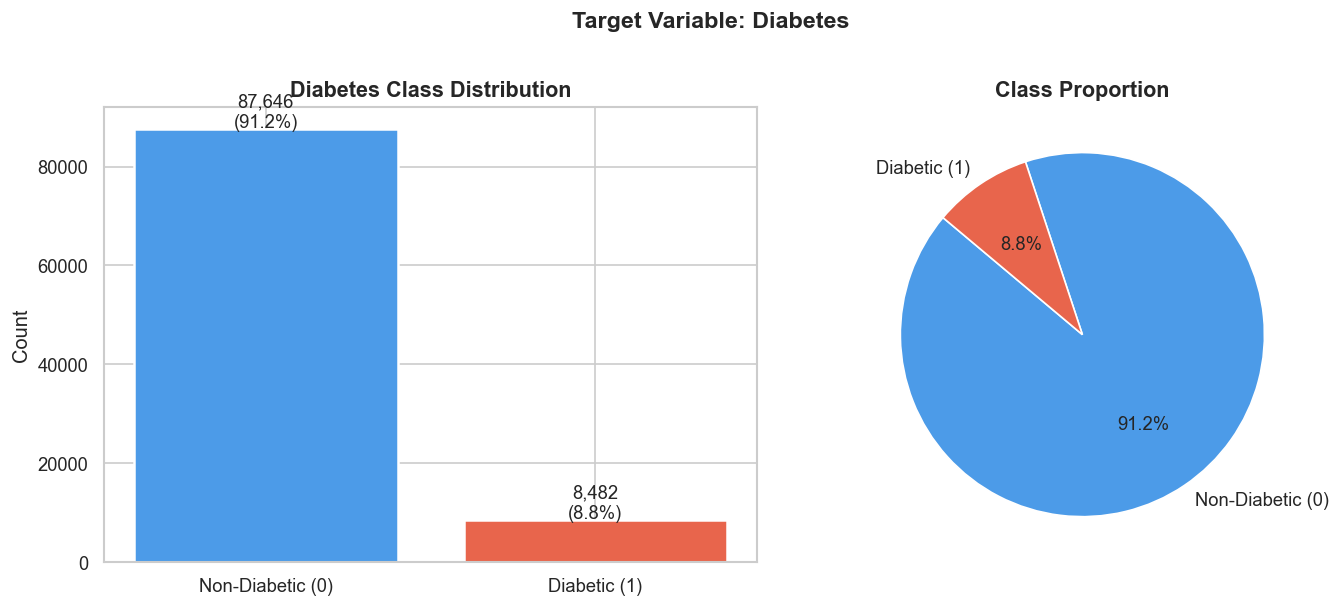

Note: Dataset is imbalanced — 91.5% Non-Diabetic vs 8.5% Diabetic.
This should be addressed during model training (e.g. class_weight="balanced").


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

counts = df['diabetes'].value_counts()
labels = ['Non-Diabetic (0)', 'Diabetic (1)']
colors = ['#4C9BE8', '#E8654C']

# Bar chart
axes[0].bar(labels, counts.values, color=colors, edgecolor='white', linewidth=1.5)
axes[0].set_title('Diabetes Class Distribution', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Count')
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 300, f'{v:,}\n({v/len(df)*100:.1f}%)', ha='center', fontsize=11)

# Pie chart
axes[1].pie(counts.values, labels=labels, colors=colors, autopct='%1.1f%%',
            startangle=140, textprops={'fontsize': 11})
axes[1].set_title('Class Proportion', fontsize=13, fontweight='bold')

plt.suptitle('Target Variable: Diabetes', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

print('Note: Dataset is imbalanced — 91.5% Non-Diabetic vs 8.5% Diabetic.')
print('This should be addressed during model training (e.g. class_weight="balanced").')

### 5.2 Distribution of Numerical Features

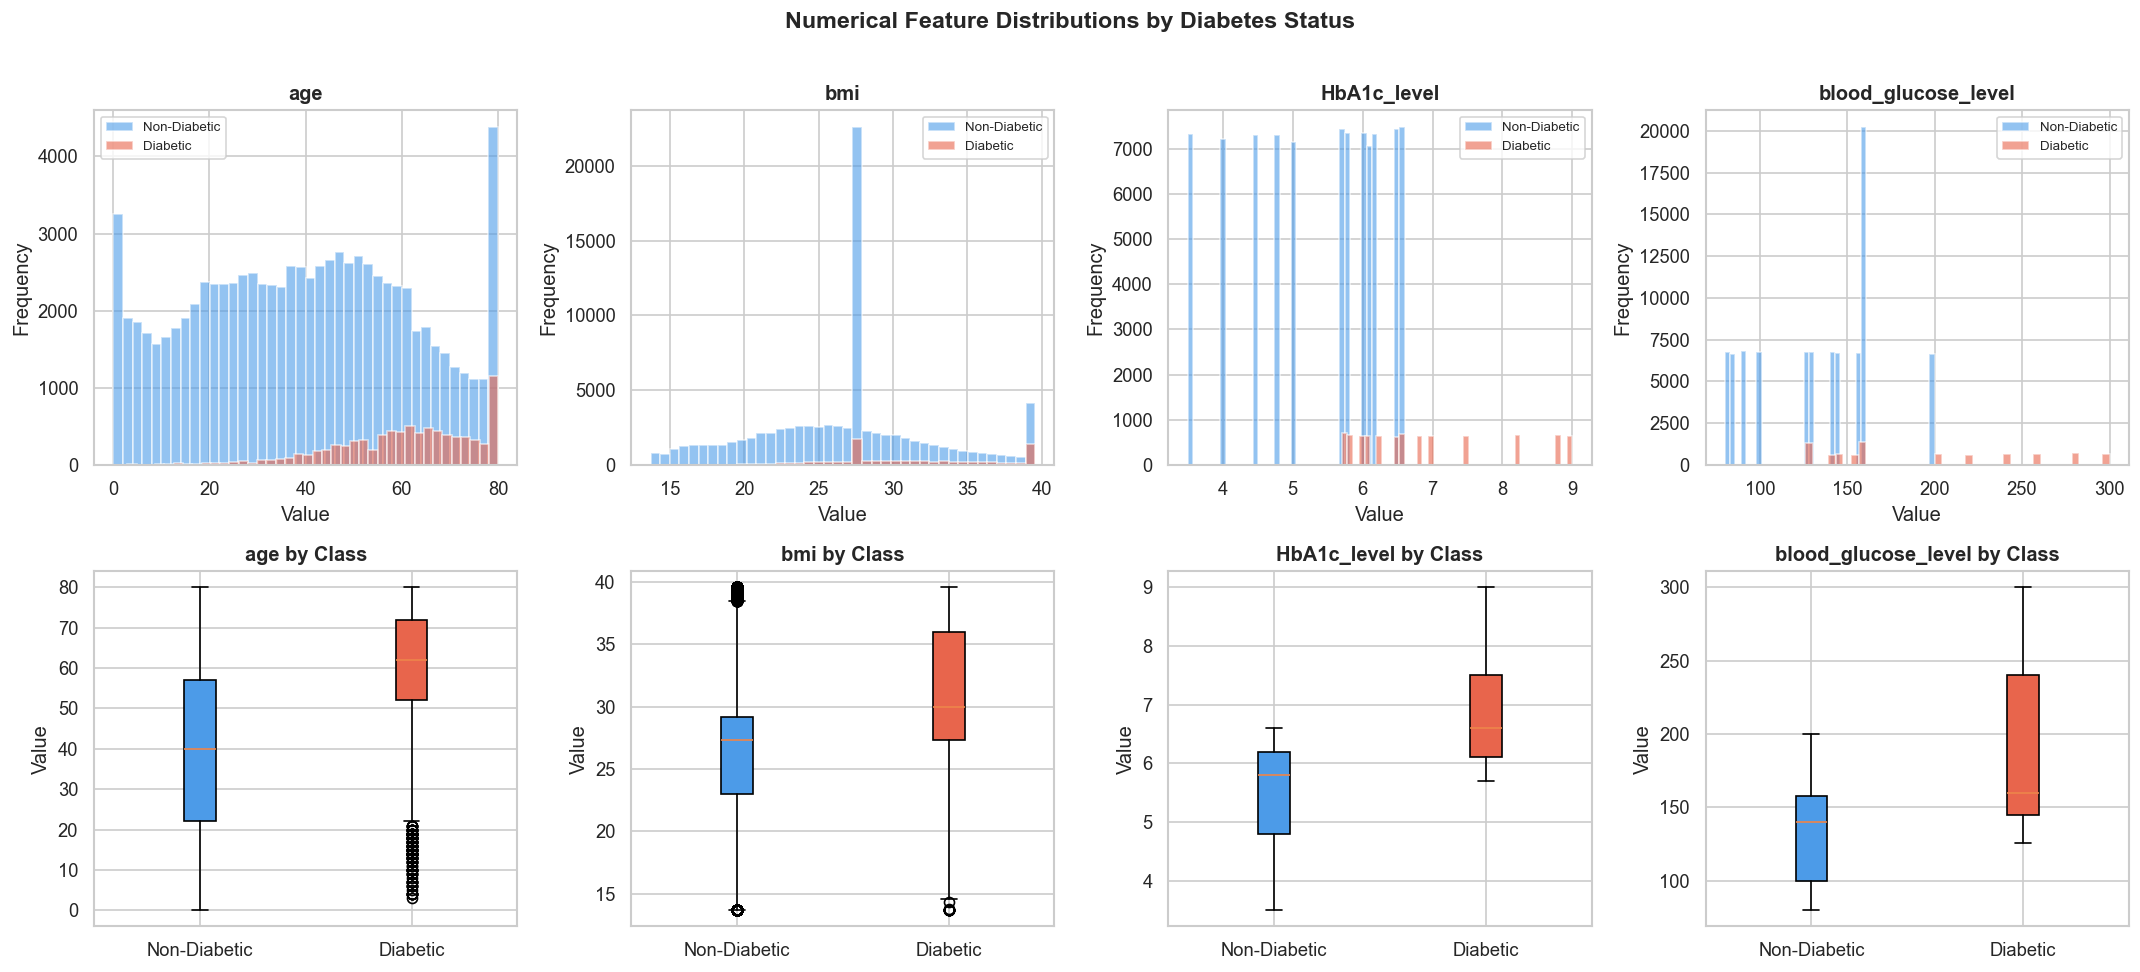

In [14]:
num_cols = ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']

fig, axes = plt.subplots(2, 4, figsize=(18, 8))

for i, col in enumerate(num_cols):
    # Histogram
    axes[0, i].hist(df[df['diabetes']==0][col], bins=40, alpha=0.6,
                    color='#4C9BE8', label='Non-Diabetic')
    axes[0, i].hist(df[df['diabetes']==1][col], bins=40, alpha=0.6,
                    color='#E8654C', label='Diabetic')
    axes[0, i].set_title(col, fontweight='bold')
    axes[0, i].legend(fontsize=8)
    axes[0, i].set_xlabel('Value')
    axes[0, i].set_ylabel('Frequency')

    # Boxplot
    data_to_plot = [df[df['diabetes']==0][col], df[df['diabetes']==1][col]]
    bp = axes[1, i].boxplot(data_to_plot, patch_artist=True,
                             labels=['Non-Diabetic', 'Diabetic'])
    bp['boxes'][0].set_facecolor('#4C9BE8')
    bp['boxes'][1].set_facecolor('#E8654C')
    axes[1, i].set_title(f'{col} by Class', fontweight='bold')
    axes[1, i].set_ylabel('Value')

plt.suptitle('Numerical Feature Distributions by Diabetes Status',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

### 5.3 Categorical Feature Analysis

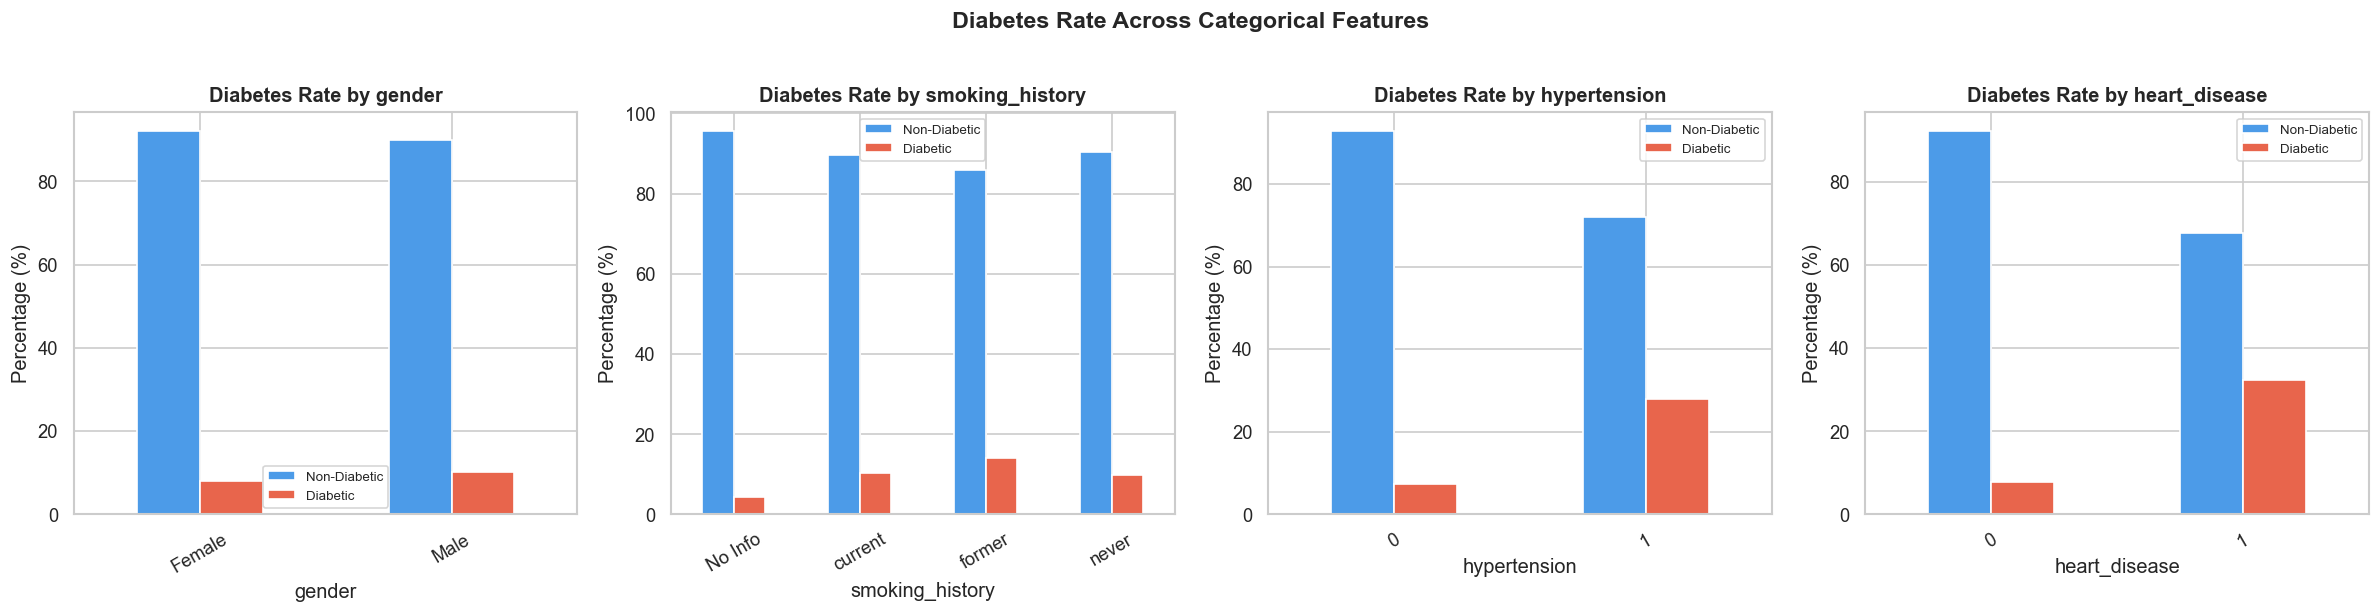

In [15]:
cat_cols = ['gender', 'smoking_history', 'hypertension', 'heart_disease']
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

for i, col in enumerate(cat_cols):
    ct = pd.crosstab(df[col], df['diabetes'], normalize='index') * 100
    ct.plot(kind='bar', ax=axes[i], color=['#4C9BE8', '#E8654C'],
            edgecolor='white', linewidth=1)
    axes[i].set_title(f'Diabetes Rate by {col}', fontweight='bold')
    axes[i].set_ylabel('Percentage (%)')
    axes[i].set_xlabel(col)
    axes[i].legend(['Non-Diabetic', 'Diabetic'], fontsize=8)
    axes[i].tick_params(axis='x', rotation=30)

plt.suptitle('Diabetes Rate Across Categorical Features',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### 5.4 Correlation Heatmap

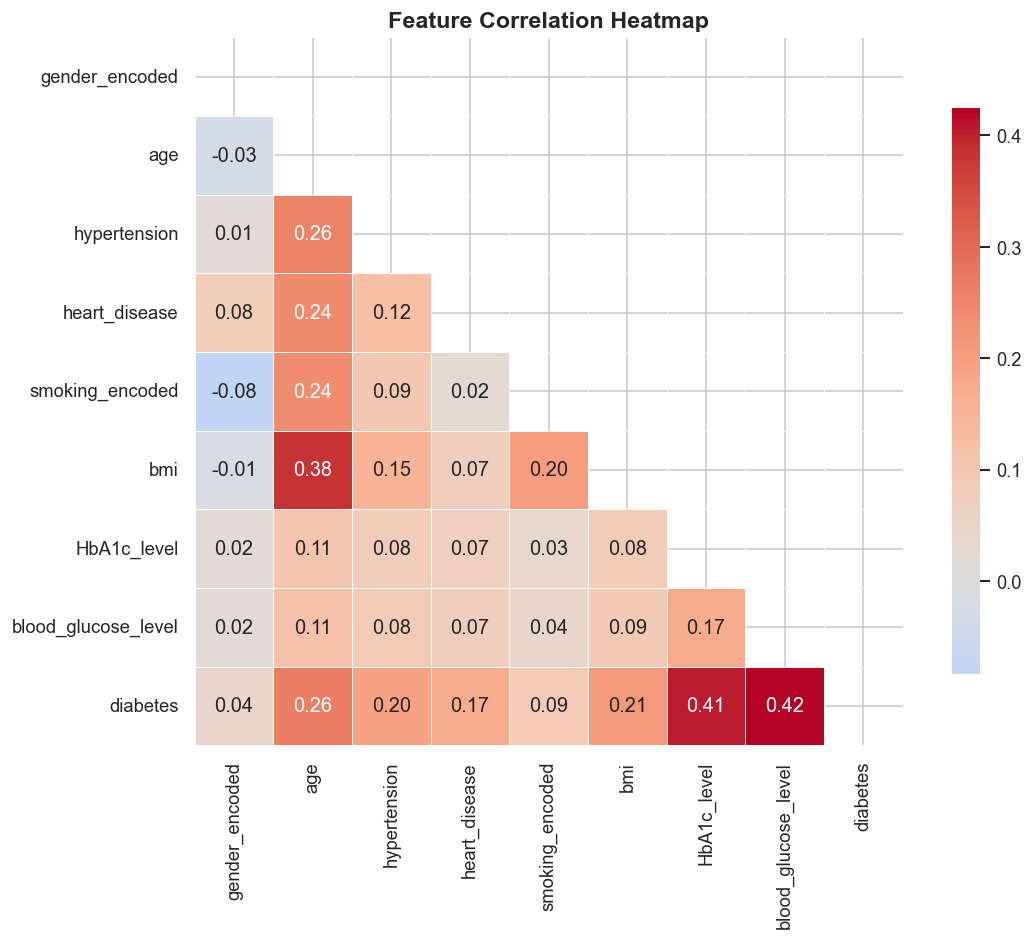

In [16]:
# Use encoded dataframe for correlation
df_encoded = df[['gender_encoded', 'age', 'hypertension', 'heart_disease',
                  'smoking_encoded', 'bmi', 'HbA1c_level',
                  'blood_glucose_level', 'diabetes']].copy()

corr = df_encoded.corr()

plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, square=True, linewidths=0.5,
            cbar_kws={'shrink': 0.8})
plt.title('Feature Correlation Heatmap', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### 5.5 Age Distribution by Diabetes Status

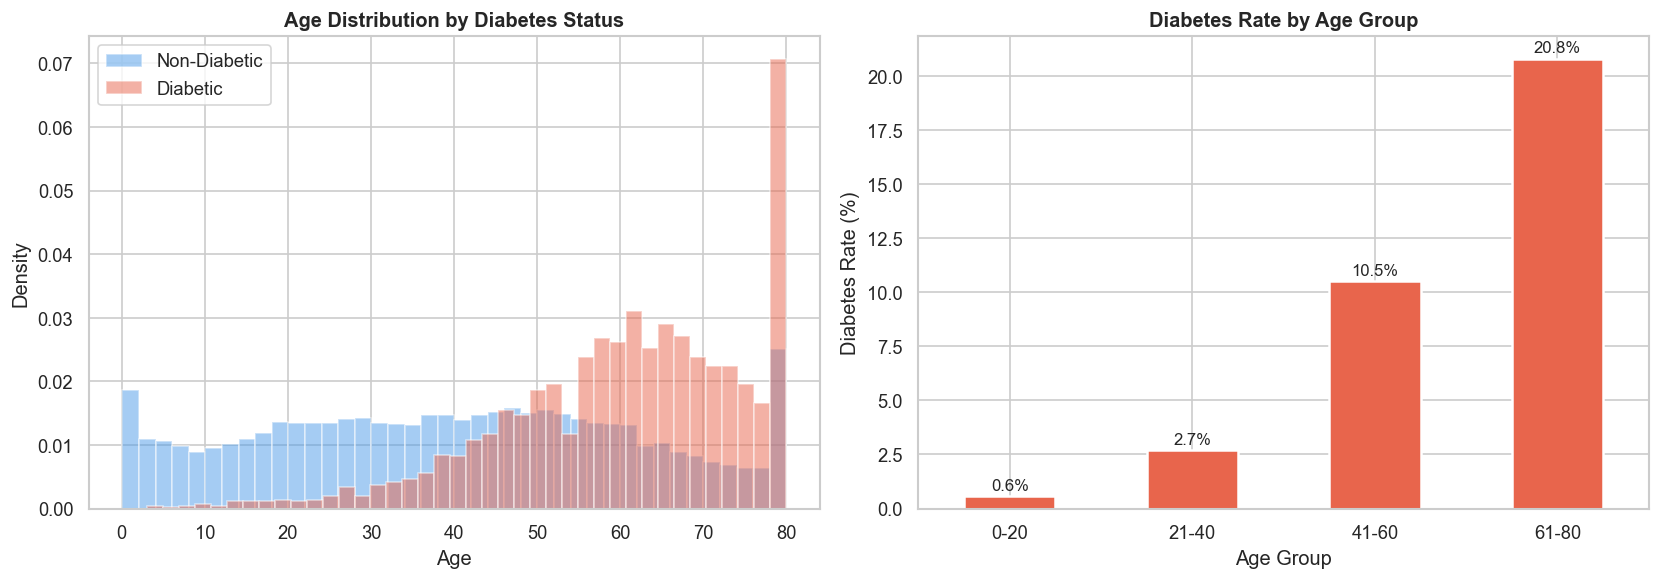

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# KDE plot
for label, color in zip([0, 1], ['#4C9BE8', '#E8654C']):
    subset = df[df['diabetes'] == label]['age']
    axes[0].hist(subset, bins=40, alpha=0.5, color=color, density=True,
                 label='Non-Diabetic' if label==0 else 'Diabetic')
axes[0].set_title('Age Distribution by Diabetes Status', fontweight='bold')
axes[0].set_xlabel('Age')
axes[0].set_ylabel('Density')
axes[0].legend()

# Diabetes rate by age group
df['age_group'] = pd.cut(df['age'], bins=[0,20,40,60,80],
                          labels=['0-20','21-40','41-60','61-80'])
rate_by_age = df.groupby('age_group')['diabetes'].mean() * 100
rate_by_age.plot(kind='bar', ax=axes[1], color='#E8654C',
                 edgecolor='white', linewidth=1.5)
axes[1].set_title('Diabetes Rate by Age Group', fontweight='bold')
axes[1].set_xlabel('Age Group')
axes[1].set_ylabel('Diabetes Rate (%)')
axes[1].tick_params(axis='x', rotation=0)
for p in axes[1].patches:
    axes[1].annotate(f'{p.get_height():.1f}%',
                     (p.get_x() + p.get_width()/2, p.get_height() + 0.3),
                     ha='center', fontsize=10)

plt.tight_layout()
plt.show()

### 5.6 BMI vs Blood Glucose Scatter (by Class)

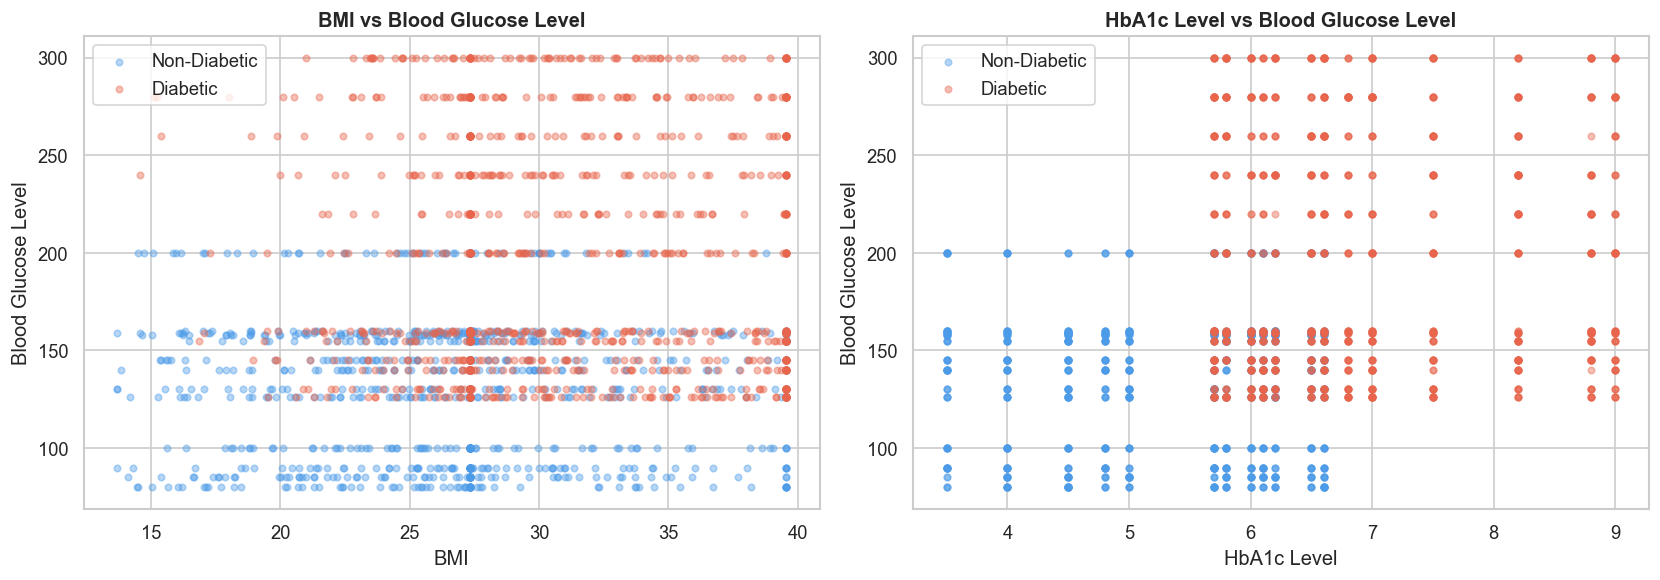

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# BMI vs Blood Glucose
for label, color, name in zip([0,1], ['#4C9BE8','#E8654C'],
                                ['Non-Diabetic','Diabetic']):
    subset = df[df['diabetes']==label].sample(1000, random_state=42)
    axes[0].scatter(subset['bmi'], subset['blood_glucose_level'],
                    alpha=0.4, color=color, label=name, s=15)
axes[0].set_title('BMI vs Blood Glucose Level', fontweight='bold')
axes[0].set_xlabel('BMI')
axes[0].set_ylabel('Blood Glucose Level')
axes[0].legend()

# HbA1c vs Blood Glucose
for label, color, name in zip([0,1], ['#4C9BE8','#E8654C'],
                                ['Non-Diabetic','Diabetic']):
    subset = df[df['diabetes']==label].sample(1000, random_state=42)
    axes[1].scatter(subset['HbA1c_level'], subset['blood_glucose_level'],
                    alpha=0.4, color=color, label=name, s=15)
axes[1].set_title('HbA1c Level vs Blood Glucose Level', fontweight='bold')
axes[1].set_xlabel('HbA1c Level')
axes[1].set_ylabel('Blood Glucose Level')
axes[1].legend()

plt.tight_layout()
plt.show()

### 5.7 Feature Importance (Correlation with Target)

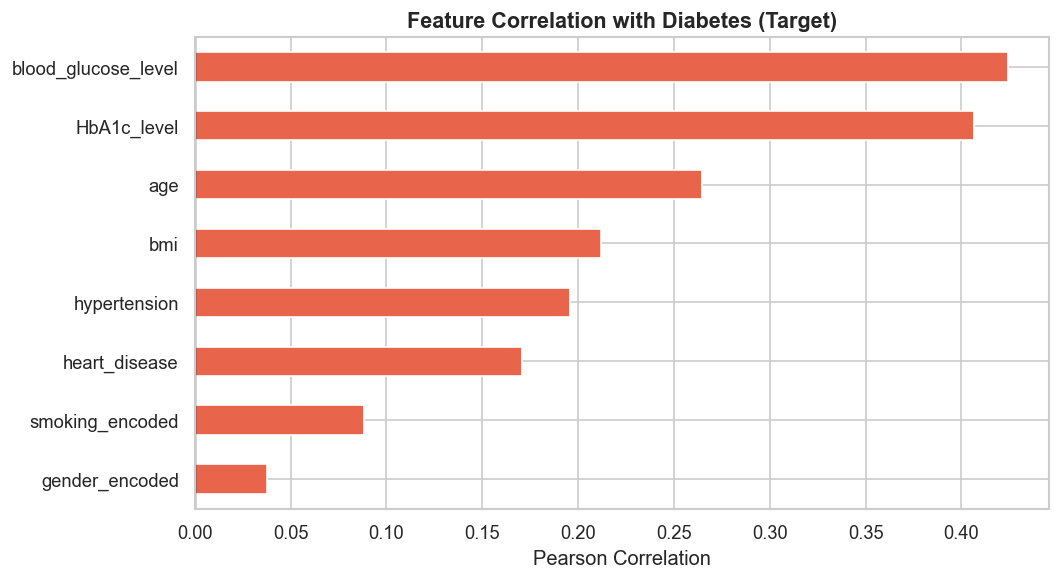

Top 3 features most correlated with diabetes:
blood_glucose_level    0.424366
HbA1c_level            0.406446
age                    0.264918
Name: diabetes, dtype: float64


In [19]:
corr_with_target = df_encoded.corr()['diabetes'].drop('diabetes').sort_values(ascending=True)

colors = ['#E8654C' if v > 0 else '#4C9BE8' for v in corr_with_target]

plt.figure(figsize=(9, 5))
corr_with_target.plot(kind='barh', color=colors, edgecolor='white', linewidth=1)
plt.title('Feature Correlation with Diabetes (Target)', fontsize=13, fontweight='bold')
plt.xlabel('Pearson Correlation')
plt.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

print('Top 3 features most correlated with diabetes:')
print(corr_with_target.abs().sort_values(ascending=False).head(3))

---
## 6. Summary of Preprocessing Steps

| Step | Action |
|---|---|
| Duplicates | Removed duplicate rows |
| Gender | Dropped 18 rows with 'Other' gender |
| Smoking History | Consolidated 6 categories → 4 meaningful groups |
| BMI Outliers | Winsorized using IQR method |
| Encoding | Label Encoding for gender and smoking_history |
| Scaling | StandardScaler on continuous features (age, bmi, HbA1c, blood_glucose) |
| Split | 70% Train / 15% Validation / 15% Test (stratified) |

## 7. Key EDA Findings

- **Class imbalance:** Only 8.5% of samples are diabetic — model should use `class_weight='balanced'`
- **Top predictors:** HbA1c level and blood glucose level are the most correlated features with diabetes
- **Age:** Diabetes rate increases significantly in the 41–60 and 61–80 age groups
- **Hypertension & heart disease:** Patients with these conditions show a notably higher diabetes rate
- **Smoking:** Former and current smokers have slightly higher diabetes rates than never-smokers
- **BMI:** Diabetic patients tend to have higher BMI, though there is overlap with non-diabetic patients

---
## 8. Export Processed Data (for Model Training)

In [20]:
# Save train/val/test splits for use in the modelling notebook
X_train.to_csv('X_train.csv', index=False)
X_val.to_csv('X_val.csv', index=False)
X_test.to_csv('X_test.csv', index=False)
y_train.to_csv('y_train.csv', index=False)
y_val.to_csv('y_val.csv', index=False)
y_test.to_csv('y_test.csv', index=False)

print('Splits saved successfully.')
print(f'  X_train: {X_train.shape}')
print(f'  X_val:   {X_val.shape}')
print(f'  X_test:  {X_test.shape}')

Splits saved successfully.
  X_train: (67289, 8)
  X_val:   (14419, 8)
  X_test:  (14420, 8)
